# Notebook 03 — Method Selection & Model Development

**Bước 4 và 5 trong Industrial AI lifecycle.**

Yêu cầu của đồ án cho bài toán RUL: so sánh **baseline regression**, **Random Forest / XGBoost** và **một phương pháp time-series phù hợp**; việc chọn phương pháp phải dựa trên *problem / data / ràng buộc công nghiệp*, không chạy theo mô hình phức tạp nhất.

Quy trình theo bài giảng 03: **Baseline → Simple Model → Candidate Models → Model Comparison → Final Candidate**.

In [1]:
import os, sys

REPO_URL = "https://github.com/duyenphung206-sudo/turbofan-rul-prediction.git"
REPO_NAME = "turbofan-rul-prediction"

# Dua thu muc lam viec ve goc du an: VS Code mo tu notebooks/, Colab tai du an tu GitHub
if not os.path.exists("src"):
    if os.path.exists("../src"):
        os.chdir("..")
    else:
        if not os.path.exists(REPO_NAME):
            os.system(f"git clone -q {REPO_URL}")
        os.chdir(REPO_NAME)
        os.system("pip install -q scikit-learn==1.9.1")   # trung phien ban luc luu mo hinh
sys.path.append(os.getcwd())
print("Thu muc lam viec:", os.getcwd())

Thu muc lam viec: /tmp/nbfix


In [2]:
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"     # an bot thong bao cua TensorFlow
from tensorflow import keras

from src.rul_utils import (
    make_sequences, regression_metrics, load_json, save_json, SENSOR_INFO,
    RUL_CAP, SEQ_LEN, RANDOM_STATE, set_plot_style, save_fig, MODEL_COLORS, MUTED, INK,
)

set_plot_style()

# Du lieu da chuan bi o Notebook 02
feat_train = pd.read_csv("data/processed/train_fd001.csv.gz")
feat_val = pd.read_csv("data/processed/val_fd001.csv.gz")
config = load_json("models/feature_config.json")
sensors, features = config["sensors"], config["features"]

X_train, y_train = feat_train[features], feat_train["RUL"]
X_val, y_val = feat_val[features], feat_val["RUL"]
print("train:", X_train.shape, "| val:", X_val.shape)

train: (16561, 42) | val: (4070, 42)


## Bước 4. Method Selection

### 4.1. Đặc điểm bài toán, dữ liệu và ràng buộc dẫn tới lựa chọn phương pháp

| Căn cứ | Đặc điểm (từ Notebook 01, 02) | Hệ quả cho việc chọn phương pháp |
|---|---|---|
| **Problem type** | Dự đoán một đại lượng liên tục (RUL, chu kỳ) | Bài toán **hồi quy có giám sát** |
| **Label availability** | Có nhãn RUL đầy đủ nhờ dữ liệu run-to-failure | Dùng được supervised learning, không cần anomaly detection |
| **Temporal structure** | Chuỗi thời gian đa biến; xuống cấp là quá trình tích lũy theo thời gian | Nên có ít nhất một phương pháp **khai thác trình tự thời gian** |
| **Data size** | ≈ 16.500 dòng train, 14 cảm biến | Đủ cho mô hình cổ điển và mạng nơ-ron **nhỏ**; không đủ cho mô hình rất lớn |
| **Data quality** | Nhiễu ≈ 6% biên độ; quan hệ cảm biến–RUL phi tuyến | Cần mô hình chịu nhiễu và bắt được phi tuyến |
| **Industrial constraint** | Dự đoán muộn nguy hiểm hơn dự đoán sớm | Ưu tiên mô hình sai số thấp ở vùng RUL nhỏ |
| **Industrial constraint** | Kỹ sư cần hiểu vì sao có cảnh báo | Mô hình càng dễ giải thích càng tốt |
| **System constraint** | Chạy trên máy cá nhân (CPU), latency < 1 giây | Loại các mô hình cần GPU hoặc quá nặng |

### 4.2. Các phương pháp ứng viên

| Vai trò | Phương pháp | Vì sao đưa vào so sánh | Interpretability | Chi phí tính toán |
|---|---|---|---|---|
| Baseline 0 | Dự đoán **giá trị trung bình** | Mốc tham chiếu tối thiểu: mô hình AI có thực sự hữu ích không? | — | ≈ 0 |
| Baseline regression | **Linear Regression** | Đơn giản nhất, minh bạch nhất (mỗi đặc trưng một hệ số) | Cao | Rất thấp |
| Machine learning | **Random Forest** | Bắt được quan hệ phi tuyến, ít phải tinh chỉnh, có feature importance | Trung bình | Trung bình |
| Time-series | **LSTM** | Đọc trực tiếp chuỗi 30 chu kỳ, tự học trình tự xuống cấp; là hướng tiếp cận phổ biến cho C-MAPSS (Zheng và cs., 2017) | Thấp | Cao hơn |

**Vì sao không chọn mô hình phức tạp hơn** (CNN-LSTM, Transformer…)? Dữ liệu chỉ có 80 động cơ train và ràng buộc chạy trên CPU; một LSTM nhỏ đã đại diện cho nhóm phương pháp chuỗi thời gian. Mục tiêu là chọn mô hình **đáp ứng yêu cầu kỹ thuật và công nghiệp**, không phải mô hình phức tạp nhất.

### 4.3. Nguyên tắc so sánh công bằng

- Cả ba mô hình dùng **cùng** tập train (80 động cơ), **cùng** tập validation (20 động cơ) và **cùng** 14 cảm biến đầu vào.
- Cả ba đều được "nhìn" 30 chu kỳ gần nhất: Linear Regression và Random Forest qua đặc trưng trượt 30 chu kỳ, LSTM qua chuỗi 30 chu kỳ.
- Dự đoán được cắt về khoảng [0, 125] vì RUL không thể âm và nhãn đã giới hạn ở 125.
- Tập **test không được dùng** trong notebook này.

## Bước 5. Model Development

### 5.0. Baseline 0 — dự đoán giá trị trung bình

In [3]:
results = {}        # chi so tren validation cua tung mo hinh
train_info = {}     # thoi gian huan luyen, so tham so, dung luong mo hinh


def show(name):
    """In MAE, RMSE, R2 tren validation cua mot mo hinh."""
    print(name, "->", {k: round(v, 2) for k, v in results[name].items() if k != "NASA_score"})


mean_rul = y_train.mean()
results["Baseline (mean)"] = regression_metrics(y_val, np.full(len(y_val), mean_rul))
print(f"Du doan moi dong = {mean_rul:.1f} chu ky")
show("Baseline (mean)")

Du doan moi dong = 87.0 chu ky
Baseline (mean) -> {'MAE': 36.93, 'RMSE': 41.72, 'R2': -0.0}


### 5.1. Mô hình 1 — Linear Regression (baseline regression)

Không có siêu tham số cần chọn.

In [4]:
t0 = time.time()
lin_reg = LinearRegression().fit(X_train, y_train)
train_info["Linear Regression"] = {"train_time_s": time.time() - t0, "n_parameters": int(lin_reg.coef_.size + 1)}

pred_val_lr = np.clip(lin_reg.predict(X_val), 0, RUL_CAP)
results["Linear Regression"] = regression_metrics(y_val, pred_val_lr)
show("Linear Regression")

Linear Regression -> {'MAE': 14.15, 'RMSE': 18.18, 'R2': 0.81}


### 5.2. Mô hình 2 — Random Forest

**Hyperparameter tuning** bằng grid search nhỏ, chọn theo RMSE trên **validation** (bài giảng 03: validation dùng để chọn cấu hình, test chỉ để đánh giá cuối).

- `max_depth`: độ sâu tối đa của cây — sâu hơn thì khớp dữ liệu hơn nhưng dễ overfitting và mô hình nặng hơn.
- `min_samples_leaf`: số mẫu tối thiểu ở mỗi lá — lớn hơn thì dự đoán mượt hơn, chịu nhiễu tốt hơn.

In [5]:
grid = []
for max_depth in [6, 10, 14]:
    for min_samples_leaf in [1, 5, 20]:
        rf = RandomForestRegressor(n_estimators=100, max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                                   n_jobs=-1, random_state=RANDOM_STATE).fit(X_train, y_train)
        rmse = regression_metrics(y_val, np.clip(rf.predict(X_val), 0, RUL_CAP))["RMSE"]
        grid.append({"max_depth": max_depth, "min_samples_leaf": min_samples_leaf, "RMSE_validation": rmse})

grid = pd.DataFrame(grid).sort_values("RMSE_validation").reset_index(drop=True)
grid.round(3)

,max_depth,min_samples_leaf,RMSE_validation
0,10,5,16.697
1,10,1,16.727
2,10,20,16.770
3,14,1,16.796
4,14,5,16.819
5,14,20,16.840
6,6,5,17.712
7,6,1,17.731
8,6,20,17.759


In [6]:
best = grid.iloc[0]
print(f"Cau hinh tot nhat: max_depth={int(best['max_depth'])}, min_samples_leaf={int(best['min_samples_leaf'])}")

t0 = time.time()
rf_model = RandomForestRegressor(n_estimators=100, max_depth=int(best["max_depth"]),
                                 min_samples_leaf=int(best["min_samples_leaf"]),
                                 n_jobs=-1, random_state=RANDOM_STATE).fit(X_train, y_train)
train_info["Random Forest"] = {
    "train_time_s": time.time() - t0,
    "n_parameters": int(sum(t.tree_.node_count for t in rf_model.estimators_)),   # tong so nut cua 100 cay
    "best_params": {"n_estimators": 100, "max_depth": int(best["max_depth"]), "min_samples_leaf": int(best["min_samples_leaf"])},
}

pred_val_rf = np.clip(rf_model.predict(X_val), 0, RUL_CAP)
results["Random Forest"] = regression_metrics(y_val, pred_val_rf)
show("Random Forest")

Cau hinh tot nhat: max_depth=10, min_samples_leaf=5


Random Forest -> {'MAE': 11.71, 'RMSE': 16.7, 'R2': 0.84}


Da luu hinh: reports/figures/03_rf_feature_importance.png


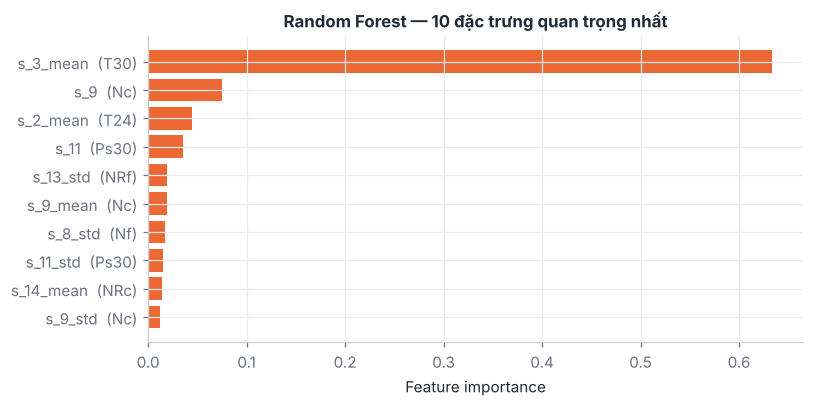

In [7]:
# Feature importance: Random Forest dua vao dac trung nao nhieu nhat?
importance = pd.Series(rf_model.feature_importances_, index=features).sort_values(ascending=False).head(10)[::-1]
labels = [f"{f}  ({SENSOR_INFO[f.split('_mean')[0].split('_std')[0]][0]})" for f in importance.index]

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh(labels, importance.values, color=MODEL_COLORS["Random Forest"])
ax.set(title="Random Forest — 10 đặc trưng quan trọng nhất", xlabel="Feature importance")
fig.tight_layout()
save_fig(fig, "03_rf_feature_importance.png")
plt.show()

**Nhận xét:** các đặc trưng quan trọng nhất đều là **trung bình trượt** (`*_mean`) của các cảm biến liên quan tới máy nén cao áp và phần nóng của động cơ — khớp với dạng hỏng HPC của FD001 và cho thấy bước feature engineering ở Notebook 02 có tác dụng.

### 5.3. Mô hình 3 — LSTM (phương pháp time-series)

**Đầu vào:** chuỗi 30 chu kỳ gần nhất × 14 cảm biến đã scale. **Đầu ra:** RUL tại chu kỳ cuối của chuỗi.

**Kiến trúc (cố ý giữ nhỏ):**

```
Input (30 chu kỳ, 14 cảm biến)
   → LSTM(64)        : đọc chuỗi theo thứ tự thời gian, nén thành 64 số tóm tắt trạng thái động cơ
   → Dropout(0.2)    : giảm overfitting
   → Dense(32, ReLU) : kết hợp phi tuyến
   → Dense(1)        : RUL dự đoán
```

**Huấn luyện:** hàm mất mát MSE, tối ưu Adam, **early stopping** theo validation (dừng khi 8 epoch liên tiếp không cải thiện và lấy lại trọng số tốt nhất) → chống overfitting mà không phải đoán số epoch.

In [8]:
X_train_seq, y_train_seq, _ = make_sequences(feat_train, sensors, SEQ_LEN)
X_val_seq, y_val_seq, _ = make_sequences(feat_val, sensors, SEQ_LEN)
print("Chuoi train:", X_train_seq.shape, "| Chuoi val:", X_val_seq.shape)

keras.utils.set_random_seed(RANDOM_STATE)       # co dinh seed de ket qua lap lai duoc

lstm_model = keras.Sequential([
    keras.layers.Input(shape=(SEQ_LEN, len(sensors))),
    keras.layers.LSTM(64),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(1),
])
lstm_model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse")
lstm_model.summary()

Chuoi train: (14241, 30, 14) | Chuoi val: (3490, 30, 14)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        20,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,337 (87.25 KB)

 Trainable params: 22,337 (87.25 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)

t0 = time.time()
history = lstm_model.fit(
    X_train_seq, y_train_seq,
    validation_data=(X_val_seq, y_val_seq),
    epochs=60, batch_size=128, callbacks=[early_stop], verbose=0,
)
train_info["LSTM"] = {
    "train_time_s": time.time() - t0,
    "n_parameters": int(lstm_model.count_params()),
    "epochs_run": len(history.history["loss"]),
}
print(f"Da huan luyen {train_info['LSTM']['epochs_run']} epoch trong {train_info['LSTM']['train_time_s']:.0f} giay")

pred_val_lstm = np.clip(lstm_model.predict(X_val_seq, verbose=0).ravel(), 0, RUL_CAP)
results["LSTM"] = regression_metrics(y_val_seq, pred_val_lstm)
show("LSTM")

Da huan luyen 35 epoch trong 71 giay


LSTM -> {'MAE': 8.7, 'RMSE': 11.96, 'R2': 0.92}


Da luu hinh: reports/figures/03_lstm_learning_curve.png


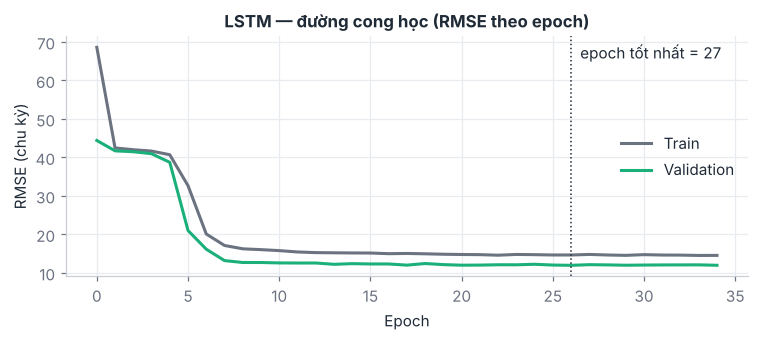

In [10]:
# Duong cong hoc: kiem tra overfitting
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(np.sqrt(history.history["loss"]), color=MUTED, label="Train")
ax.plot(np.sqrt(history.history["val_loss"]), color=MODEL_COLORS["LSTM"], label="Validation")
best_epoch = int(np.argmin(history.history["val_loss"]))
ax.axvline(best_epoch, color=INK, linestyle=":", linewidth=1)
ax.text(best_epoch + 0.5, ax.get_ylim()[1] * 0.92, f"epoch tốt nhất = {best_epoch + 1}", color=INK)
ax.set(title="LSTM — đường cong học (RMSE theo epoch)", xlabel="Epoch", ylabel="RMSE (chu kỳ)")
ax.legend()
fig.tight_layout()
save_fig(fig, "03_lstm_learning_curve.png")
plt.show()

## 5.4. So sánh trên tập validation

> Lưu ý: Linear Regression và Random Forest dự đoán được từ chu kỳ đầu tiên; LSTM cần đủ 30 chu kỳ lịch sử nên chỉ dự đoán từ chu kỳ thứ 30 trở đi. Đây là một **giới hạn vận hành** của LSTM và được tính đến khi đánh giá ở Notebook 04.

In [11]:
val_table = pd.DataFrame(results).T[["MAE", "RMSE", "R2"]]
val_table["train_time_s"] = [0.0] + [train_info[m]["train_time_s"] for m in ["Linear Regression", "Random Forest", "LSTM"]]
val_table.round(2)

,MAE,RMSE,R2,train_time_s
Baseline (mean),36.93,41.72,-0.00,0.00
Linear Regression,14.15,18.18,0.81,0.03
Random Forest,11.71,16.70,0.84,10.71
LSTM,8.70,11.96,0.92,70.67


Da luu hinh: reports/figures/03_validation_rmse.png


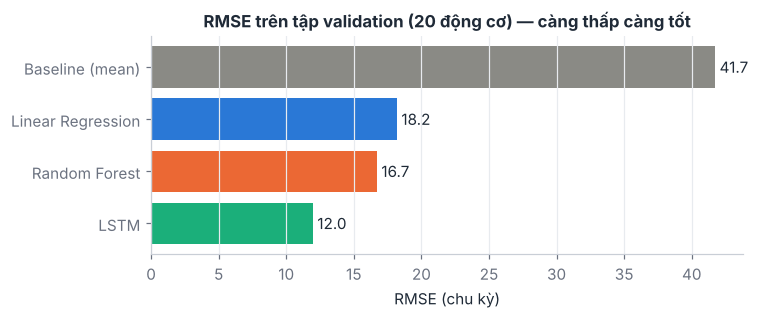

In [12]:
fig, ax = plt.subplots(figsize=(7, 3))
names = list(results.keys())
bars = ax.barh(names[::-1], [results[n]["RMSE"] for n in names[::-1]], color=[MODEL_COLORS[n] for n in names[::-1]])
ax.bar_label(bars, fmt="%.1f", padding=3)
ax.set(title="RMSE trên tập validation (20 động cơ) — càng thấp càng tốt", xlabel="RMSE (chu kỳ)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
save_fig(fig, "03_validation_rmse.png")
plt.show()

Da luu hinh: reports/figures/03_prediction_example.png


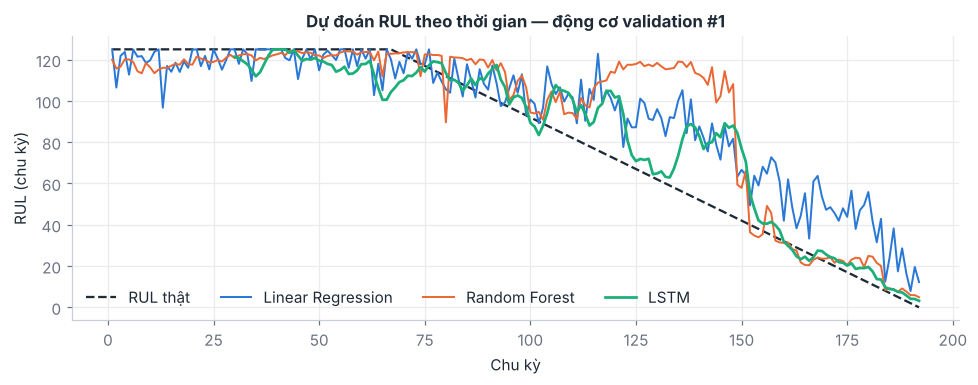

In [13]:
# Minh hoa: du doan cua 3 mo hinh tren 1 dong co validation
unit = config["val_units"][0]
g = feat_val[feat_val["unit"] == unit].reset_index(drop=True)
seq_g, _, _ = make_sequences(g, sensors, SEQ_LEN)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(g["cycle"], g["RUL"], color=INK, linestyle="--", linewidth=1.5, label="RUL thật")
ax.plot(g["cycle"], np.clip(lin_reg.predict(g[features]), 0, RUL_CAP), color=MODEL_COLORS["Linear Regression"], linewidth=1.3, label="Linear Regression")
ax.plot(g["cycle"], np.clip(rf_model.predict(g[features]), 0, RUL_CAP), color=MODEL_COLORS["Random Forest"], linewidth=1.3, label="Random Forest")
ax.plot(g["cycle"][SEQ_LEN - 1:], np.clip(lstm_model.predict(seq_g, verbose=0).ravel(), 0, RUL_CAP), color=MODEL_COLORS["LSTM"], linewidth=1.8, label="LSTM")
ax.set(title=f"Dự đoán RUL theo thời gian — động cơ validation #{unit}", xlabel="Chu kỳ", ylabel="RUL (chu kỳ)")
ax.legend(ncol=4, loc="lower left")
fig.tight_layout()
save_fig(fig, "03_prediction_example.png")
plt.show()

## 5.5. Lưu mô hình

| File | Nội dung |
|---|---|
| `models/linear_regression.joblib` | Linear Regression |
| `models/random_forest.joblib` | Random Forest (cấu hình tốt nhất) |
| `models/lstm.keras` | LSTM |
| `reports/training_summary.json` | Kết quả validation, thời gian huấn luyện, số tham số |

In [14]:
os.makedirs("reports", exist_ok=True)
joblib.dump(lin_reg, "models/linear_regression.joblib")
joblib.dump(rf_model, "models/random_forest.joblib", compress=3)
lstm_model.save("models/lstm.keras")

for name, path in [("Linear Regression", "models/linear_regression.joblib"),
                   ("Random Forest", "models/random_forest.joblib"),
                   ("LSTM", "models/lstm.keras")]:
    train_info[name]["model_size_mb"] = os.path.getsize(path) / 1e6

save_json({"validation_metrics": results, "train_info": train_info, "mean_rul_train": float(mean_rul)},
          "reports/training_summary.json")
pd.DataFrame(train_info).T[["train_time_s", "n_parameters", "model_size_mb"]]

,train_time_s,n_parameters,model_size_mb
Linear Regression,0.033329,43.0,0.001927
Random Forest,10.711424,95432,2.228315
LSTM,70.667131,22337.0,0.299438


## Kết luận

- Cả ba mô hình đều tốt hơn rõ rệt so với baseline dự đoán trung bình → việc dùng AI **có ý nghĩa**.
- Thứ tự trên validation: **LSTM < Random Forest < Linear Regression** (RMSE càng thấp càng tốt). LSTM chính xác nhất nhưng huấn luyện lâu nhất và khó giải thích nhất.
- Linear Regression với đặc trưng trượt chỉ kém Random Forest một khoảng nhỏ → feature engineering tốt giúp mô hình đơn giản vẫn cạnh tranh được.
- **Chưa chọn mô hình cuối ở đây.** Quyết định cuối cùng được đưa ra ở Notebook 04 sau khi đánh giá đủ 3 mức: model-level, system-level và industrial-level.